# Stress and Emotion Detection using Physiological Signals 

### Project No : 1

Classifying **Baseline / Stress / Amusement** states from chest-worn physiological sensor data (ECG, EDA, EMG, RESP, TEMP, ACC) using classical ML models.

---

### Dataset: WESAD (Wearable Stress and Affect Detection) — Chest (RespiBAN) signals only

**Course Title:** AI-Enabled Healthcare for Industrial Readiness 

---

### 1. Project Introduction

Stress is a major contributor to poor mental and physical health, and the ability to detect it automatically from wearable sensor data has wide applications in healthcare, workplace wellness, and IoT-based personal health monitoring.

This project builds a complete **end-to-end machine learning pipeline** that:
1. Loads raw physiological signal data from the WESAD dataset
2. Extracts meaningful statistical features from ECG, EDA, EMG, Respiration, and Temperature signals
3. Trains and compares multiple ML classifiers **(Logistic Regression, SVM, Random Forest, XGBoost)**
4. Evaluates and selects the best-performing model for 3-class emotion/stress classification

---

### 2. Problem Statement

**Given** raw chest-worn physiological sensor signals (ECG, EDA, EMG, Respiration, Temperature, Accelerometer) sampled at 700 Hz from multiple subjects

**Classify** each time-window of signal data into one of three affective/stress states

| Class | Label | Description |
|---|---|---|
| 0 | Baseline | Calm, neutral resting state |
| 1 | Stress | Induced via public speaking + mental arithmetic (TSST protocol) |
| 2 | Amusement | Induced via watching funny video clips |


**Type of problem:** Multi-class supervised classification (3 classes)

**Input:** Engineered statistical features per time-window (not raw signal)

**Output:** Predicted class label (Baseline / Stress / Amusement)

---

### 3. Dataset Description

**Dataset:** Wearable Stress and Affect Detection (**WESAD**)

**Source:** Schmidt et al., 2018 — UCI Machine Learning Repository

**Citation:** Philip Schmidt, Attila Reiss, Robert Duerichen, Claus Marberger and Kristof Van Laerhoven, "Introducing WESAD, a multimodal dataset for Wearable Stress and Affect Detection", ICMI 2018, Boulder, USA, 2018.

**Download:** https://archive.ics.uci.edu/dataset/465/wesad+wearable+stress+and+affect+detection

**Device:** The Raw sensor data was recorded with two devices: a chest-worn device (RespiBAN) and a wrist-worn device (Empatica E4).
The RespiBAN device provides the following sensor data: electrocardiogram (ECG), electrodermal activity (EDA), electromyogram (EMG), respiration, body temperature, and three-axis acceleration. All signals are sampled at 700 Hz.
The Empatica E4 device provides the following sensor data: blood volume pulse (BVP, 64 Hz), electrodermal activity (EDA, 4 Hz), body temperature (4 Hz), and three-axis acceleration (32 Hz). 

Thanks to the creators of this dataset **Philip Schmidt, Attila Reiss, Robert Duerichen, Claus Marberger, Kristof Van Laerhoven**

**RespiBAN (Chest-worn)** - used in this project. Sampling rate: 700 Hz for all signals and it was feeded by (RespiBAN Professional)  

**Signals used:**

| Signal | Description |
|---|---|
| ECG | Electrocardiogram — heart electrical activity |
| EDA | Electrodermal Activity — skin conductance (sweat response) |
| EMG | Electromyogram — muscle activity |
| RESP | Respiration — chest expansion/contraction (breathing) |
| TEMP | Body temperature |
| ACC | 3-axis accelerometer (movement) |


**File format:** Each subject has an `SX.pkl` file — a Python dictionary containing `signal['chest']` (dict of arrays), `label` (array of condition codes), and `subject` (ID string).

**Labels used in this project (3-class):**
- `1` → Baseline
- `2` → Stress
- `3` → Amusement

(Labels `0, 4, 5, 6, 7` — transient/meditation/recovery — are dropped.)

---

### 4. Data Loading

Due to cloud storage limitations and high storage considerations, I am using a synthetic data generator. If you have downloaded the dataset from the source, please change the following steps
#### How to get the data onto your machine
1. Download the ZIP from the UCI link above.
2. Extract it. You'll get folders `S2/`, `S3/`, ... `S17/`.
3. Copy just the `SX.pkl` file from each folder into a single folder named `stress-emotion-detection-wesad/data/raw/` next to this notebook.
4. Update `DATA_DIR` in the next section if your path differs.

Once you have the real WESAD files, set it to `False` and point `DATA_DIR` to your data folder.

**Note:** If you haven't downloaded WESAD yet, set `USE_SYNTHETIC_DATA = True` below — this generates realistic synthetic physiological data so you can run and test the ENTIRE pipeline immediately.

However, for authentic performance evaluation and benchmarking, it is highly recommended to eventually run the pipeline using the actual WESAD dataset by toggling this flag to `False`

---

In [1]:
import os
import pickle
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import signal as scipy_signal
from scipy.stats import skew, kurtosis

import warnings
warnings.filterwarnings("ignore")

sns.set_style("whitegrid")
plt.rcParams["figure.figsize"] = (10, 5)

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

#### 4.1 Dataset Configuration

Maintain the file structure as Mentioned in the README.md File and Extract the Sx.pkl from every Folder and Here s1.pkl and s12.pkl are ignored officially 

In [2]:
USE_SYNTHETIC_DATA = False   

notebook_dir = os.getcwd()                       
project_root = os.path.dirname(notebook_dir)     
DATA_DIR = os.path.join(project_root, "data", "raw")

FS = 700                    
SUBJECTS = [f"S{i}" for i in [2,3,4,5,6,7,8,9,10,11,13,14,15,16,17]]  
LABEL_MAP = {1: "Baseline", 2: "Stress", 3: "Amusement"}
KEEP_LABELS = [1, 2, 3]

#### 4.2 Synthetic Data Generator

Fallback so the notebook runs end-to-end without the real dataset 

Generates fake but realistic-looking chest signal data for one subject,
    cycling through ``Baseline -> Stress -> Amusement`` so the pipeline is testable

In [3]:
def generate_synthetic_subject(subject_id, duration_sec=300, fs=FS, seed=0):
    rng = np.random.RandomState(seed)
    n = duration_sec * fs
    t = np.arange(n) / fs

    third = n // 3  
    label = np.concatenate([
        np.full(third, 1),                 # Baseline
        np.full(third, 2),                 # Stress
        np.full(n - 2 * third, 3)          # Amusement
    ])

    # Simulate ECG-like signal: higher heart rate & noise during stress
    hr_baseline, hr_stress, hr_amuse = 70, 95, 80
    hr_profile = np.where(label == 1, hr_baseline, np.where(label == 2, hr_stress, hr_amuse))
    ecg = np.sin(2 * np.pi * (hr_profile / 60) * t) + rng.normal(0, 0.15, n)

    # EDA: rises during stress
    eda_base = np.where(label == 1, 2.0, np.where(label == 2, 6.0, 3.5))
    eda = eda_base + rng.normal(0, 0.3, n) + np.cumsum(rng.normal(0, 0.001, n))

    # EMG: more muscle tension during stress
    emg_base = np.where(label == 1, 0.02, np.where(label == 2, 0.08, 0.04))
    emg = emg_base * rng.normal(1, 0.5, n)

    # Respiration: faster, shallower breathing during stress
    resp_rate = np.where(label == 1, 14, np.where(label == 2, 22, 17))
    resp = np.sin(2 * np.pi * (resp_rate / 60) * t) + rng.normal(0, 0.1, n)

    # Temperature: slight drop during stress (vasoconstriction)
    temp_base = np.where(label == 1, 33.0, np.where(label == 2, 32.4, 32.8))
    temp = temp_base + rng.normal(0, 0.05, n)

    # Accelerometer: more movement during amusement (laughing) and stress (talking)
    acc_mag = np.where(label == 1, 0.02, np.where(label == 2, 0.05, 0.06))
    acc_x = acc_mag * rng.normal(0, 1, n)
    acc_y = acc_mag * rng.normal(0, 1, n)
    acc_z = 1.0 + acc_mag * rng.normal(0, 1, n)  # gravity baseline on z

    return {
        "signal": {
            "chest": {
                "ECG": ecg.reshape(-1, 1),
                "EDA": eda.reshape(-1, 1),
                "EMG": emg.reshape(-1, 1),
                "Resp": resp.reshape(-1, 1),
                "Temp": temp.reshape(-1, 1),
                "ACC": np.stack([acc_x, acc_y, acc_z], axis=1)
            }
        },
        "label": label,
        "subject": subject_id
    } 

#### 4.3 Loading all the Subjects
Whether its Synthetic or Orignal , It Loads all the subjects details for the further Processing


In [4]:
def load_subject(subject_id, seed=0):
    if USE_SYNTHETIC_DATA:
        return generate_synthetic_subject(subject_id, seed=seed)
    else:
        path = os.path.join(DATA_DIR, f"{subject_id}.pkl")
        with open(path, "rb") as f:
            data = pickle.load(f, encoding="latin1")
        return data

raw_data = {}
for i, sid in enumerate(SUBJECTS):
    raw_data[sid] = load_subject(sid, seed=i)

print(f"Loaded {len(raw_data)} subjects: {list(raw_data.keys())}")
print(f"Example signal keys for {SUBJECTS[0]}: {list(raw_data[SUBJECTS[0]]['signal']['chest'].keys())}")
print(f"ECG shape for {SUBJECTS[0]}: {raw_data[SUBJECTS[0]]['signal']['chest']['ECG'].shape}")

Loaded 15 subjects: ['S2', 'S3', 'S4', 'S5', 'S6', 'S7', 'S8', 'S9', 'S10', 'S11', 'S13', 'S14', 'S15', 'S16', 'S17']
Example signal keys for S2: ['ACC', 'ECG', 'EMG', 'EDA', 'Temp', 'Resp']
ECG shape for S2: (4255300, 1)


#### 4.4 Sampling Frequency & Recording Duration (per subject)
1. **Sampling frequency** — fixed at 700 Hz for all chest (RespiBAN) signals (same across every subject, since this is a hardware-level setting).
2. **Recording duration** — this **varies per subject**, since each person took a different amount of time during the Baseline / Stress / Amusement protocol phases (e.g., some people spoke faster during the stress test, others took longer reading the magazine in Baseline).

In [5]:
duration_records = []
for sid in SUBJECTS:
    n_samples = len(raw_data[sid]["label"])
    duration_sec = n_samples / FS
    duration_min = duration_sec / 60
    duration_records.append({
        "Subject": sid,
        "Sampling Frequency (Hz)": FS,
        "Total Samples": n_samples,
        "Duration (seconds)": round(duration_sec, 1),
        "Duration (minutes)": round(duration_min, 2)
    })

duration_df = pd.DataFrame(duration_records)
print(f"Sampling Frequency (fixed, all subjects): {FS} Hz\n")
print("Recording duration per subject (varies by subject, as expected):")
duration_df

Sampling Frequency (fixed, all subjects): 700 Hz

Recording duration per subject (varies by subject, as expected):


,Subject,Sampling Frequency (Hz),Total Samples,Duration (seconds),Duration (minutes)
0,S2,700,4255300,6079.0,101.32
1,S3,700,4545100,6493.0,108.22
2,S4,700,4496100,6423.0,107.05
3,S5,700,4380600,6258.0,104.30
4,S6,700,4949700,7071.0,117.85
5,S7,700,3666600,5238.0,87.30
6,S8,700,3826200,5466.0,91.10
7,S9,700,3656100,5223.0,87.05
8,S10,700,3847200,5496.0,91.60
9,S11,700,3663100,5233.0,87.22


### 5.Exploratory Data Analysis (Raw Signals)
#### 5.1 Raw Signal Comparison Across Conditions on the Subject 
Before extracting features, let's visualize the raw signals to understand how they behave differently across Baseline, Stress, and Amusement conditions. This builds intuition for which features will be useful later.

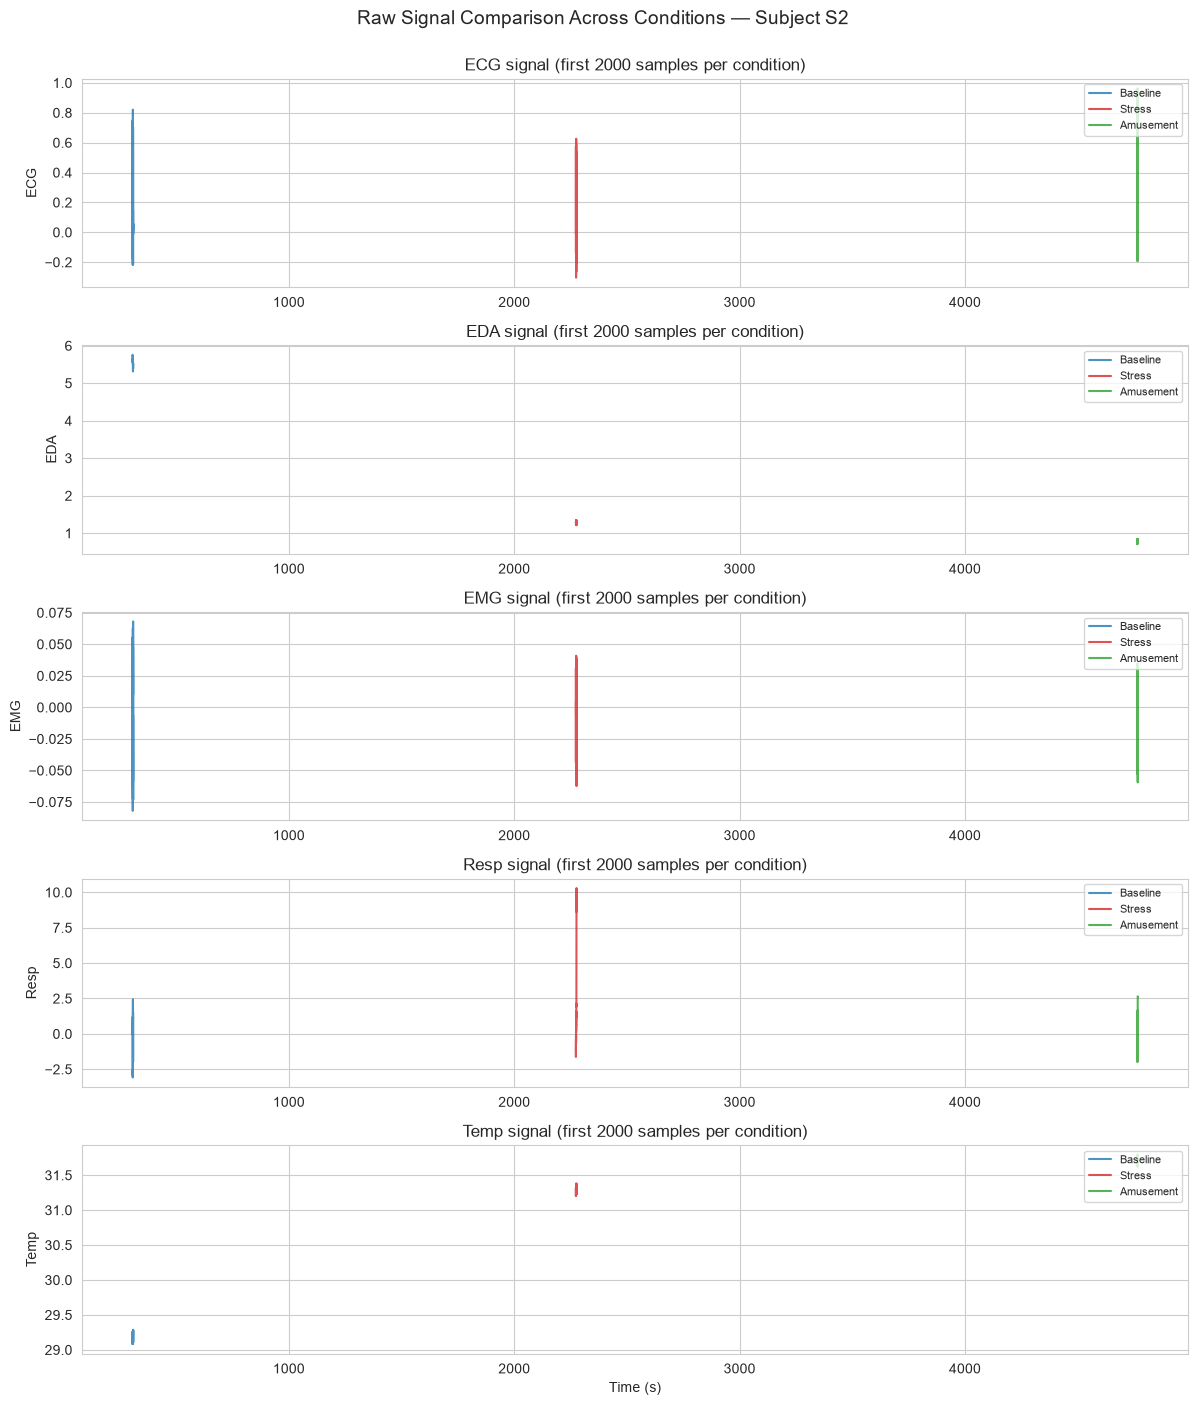

In [6]:
sample_subject = SUBJECTS[0]
data = raw_data[sample_subject]
label_arr = data["label"]
chest = data["signal"]["chest"]

fig, axes = plt.subplots(5, 1, figsize=(12, 14), sharex=False)
signals_to_plot = ["ECG", "EDA", "EMG", "Resp", "Temp"]
colors = {1: "tab:blue", 2: "tab:red", 3: "tab:green"}

for ax, sig_name in zip(axes, signals_to_plot):
    sig = chest[sig_name].flatten()
    for lbl in [1, 2, 3]:
        idx = np.where(label_arr == lbl)[0]
        if len(idx) > 0:
            ax.plot(idx[:2000] / FS, sig[idx[:2000]], color=colors[lbl], label=LABEL_MAP[lbl], alpha=0.8)
    ax.set_title(f"{sig_name} signal (first 2000 samples per condition)")
    ax.set_ylabel(sig_name)
    ax.legend(loc="upper right", fontsize=8)

axes[-1].set_xlabel("Time (s)") 

plt.suptitle(f"Raw Signal Comparison Across Conditions — Subject {sample_subject}", y=1.0, fontsize=14)
plt.tight_layout()
plt.show()

#### 5.2 Raw Class Distribution (Before Windowing)
Class distribution across all subjects (sample counts per label)

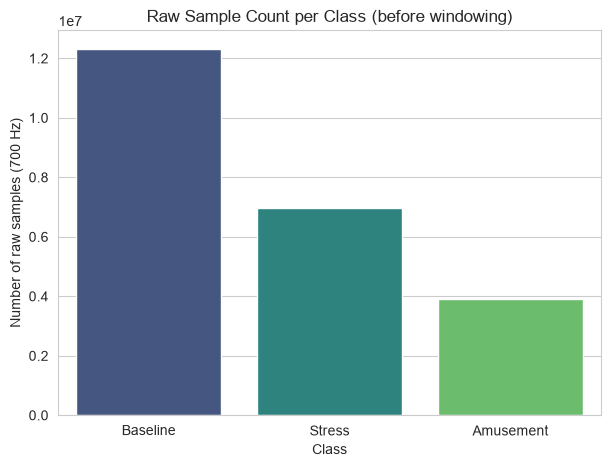

{'Baseline': np.int64(12327702), 'Stress': np.int64(6976201), 'Amusement': np.int64(3902501)}


In [7]:
label_counts = {}
for sid in SUBJECTS:
    lbl = raw_data[sid]["label"]
    for l in KEEP_LABELS:
        label_counts[LABEL_MAP[l]] = label_counts.get(LABEL_MAP[l], 0) + np.sum(lbl == l)

plt.figure(figsize=(7, 5))
sns.barplot(x=list(label_counts.keys()), y=list(label_counts.values()), palette="viridis")
plt.title("Raw Sample Count per Class (before windowing)")
plt.ylabel("Number of raw samples (700 Hz)")
plt.xlabel("Class")
plt.show()

print(label_counts)

### 6. Data Cleaning
At the raw signal level, cleaning means:
1. **Dropping unwanted labels** (0, 4, 5, 6, 7) — these are transient/meditation/recovery periods we're not classifying.
2. **Checking for NaNs/Infs** in raw signals (sensor dropouts).
3. **Windowing** the continuous signal into fixed-size chunks — this is also where most "noise" gets naturally smoothed out since we compute statistics over each window rather than using raw points directly.

We use **60-second windows with 50% overlap**. This window size is long enough to capture stable HRV and EDA trends, while still giving us enough total windows across 15 subjects for ML training.

Handling the sensor dropouts by substituting `0.0` a standard placeholder to preserve array length without biasing variance calculations.

In [8]:
def clean_subject_signal(data):
    label_arr = data["label"]
    chest = data["signal"]["chest"]

    mask = np.isin(label_arr, KEEP_LABELS)

    cleaned_chest = {}
    for sig_name, arr in chest.items():
        arr = np.nan_to_num(arr, nan=0.0, posinf=0.0, neginf=0.0)  # handle sensor dropouts
        cleaned_chest[sig_name] = arr[mask]

    cleaned_label = label_arr[mask]
    return cleaned_chest, cleaned_label

cleaned_data = {}
for sid in SUBJECTS:
    chest_clean, label_clean = clean_subject_signal(raw_data[sid])
    cleaned_data[sid] = {"chest": chest_clean, "label": label_clean}

print("Cleaning complete.")
print(f"{SUBJECTS[0]} cleaned ECG shape: {cleaned_data[SUBJECTS[0]]['chest']['ECG'].shape}")
print(f"{SUBJECTS[0]} unique labels after cleaning: {np.unique(cleaned_data[SUBJECTS[0]]['label'])}")

Cleaning complete.
S2 cleaned ECG shape: (1484700, 1)
S2 unique labels after cleaning: [1 2 3]


#### 6.1 Windowing Funtction
Slices each signal & label array into overlapping fixed-size windows. 

`A window's label = majority label within that window (handles boundary windows)`.

**Expected output:** Several hundred windows total (exact count depends on session lengths), roughly balanced across the 3 classes since WESAD's protocol phases are designed to be comparable in duration.

In [9]:
WINDOW_SEC = 60
OVERLAP = 0.5
WINDOW_SIZE = WINDOW_SEC * FS
STEP_SIZE = int(WINDOW_SIZE * (1 - OVERLAP))

def create_windows(chest_signals, label_arr, window_size=WINDOW_SIZE, step_size=STEP_SIZE):
    """Slices each signal + label array into overlapping fixed-size windows.
    A window's label = majority label within that window (handles boundary windows)."""
    n_samples = len(label_arr)
    windows = []
    window_labels = []

    for start in range(0, n_samples - window_size, step_size):
        end = start + window_size
        window_label_segment = label_arr[start:end]
        # majority vote for the window's label
        values, counts = np.unique(window_label_segment, return_counts=True)
        majority_label = values[np.argmax(counts)]

        # only keep "pure" windows (>=90% one label) to avoid ambiguous transition windows
        if counts.max() / len(window_label_segment) >= 0.9:
            window_dict = {sig: arr[start:end] for sig, arr in chest_signals.items()}
            windows.append(window_dict)
            window_labels.append(majority_label)

    return windows, window_labels

print(f"Window size: {WINDOW_SIZE} samples ({WINDOW_SEC} seconds)")
print(f"Step size: {STEP_SIZE} samples ({STEP_SIZE/FS:.1f} seconds, {int(OVERLAP*100)}% overlap)")

Window size: 42000 samples (60 seconds)
Step size: 21000 samples (30.0 seconds, 50% overlap)


#### 6.2 Applying Windowing Function to All subjects

In [10]:
all_windows = []   # list of (subject_id, window_dict)
all_labels = []    # corresponding labels
all_subjects = []  # corresponding subject id (needed for subject-wise split later)

for sid in SUBJECTS:
    windows, labels = create_windows(cleaned_data[sid]["chest"], cleaned_data[sid]["label"])
    all_windows.extend(windows)
    all_labels.extend(labels)
    all_subjects.extend([sid] * len(windows))

print(f"Total windows created across all subjects: {len(all_windows)}")
print(f"Label distribution:  {pd.Series(all_labels).map(LABEL_MAP).value_counts()}")

Total windows created across all subjects: 1035
Label distribution:  Baseline     568
Stress       306
Amusement    161
Name: count, dtype: int64


### 7. Feature Engineering

Raw signal windows (thousands of points each) can't be fed directly into classical ML models effectively. Instead, we compute **statistical features** that summarize each window — this is standard practice in physiological signal ML.

**Features extracted per signal:**

| Signal | Features |
|---|---|
| ECG | Mean Heart Rate, HRV (SDNN, RMSSD), mean, std |
| EDA | Mean, std, slope (trend), min, max |
| EMG | Mean, std, energy (mean of squared signal) |
| Resp | Mean, std, estimated breathing rate |
| Temp | Mean, std, slope |
| ACC | Mean magnitude, std of magnitude |

**Expected output:** A DataFrame where each row = one 60-second window, columns = ~18 engineered features + `label` + `subject` + `label_name`. 

#### 7.1 Feature Extraction Functions 

In [11]:
def detect_ecg_peaks(ecg_signal, fs=FS):
    """Simple R-peak detector using scipy's find_peaks with a minimum distance
    constraint (assumes heart rate won't exceed 200 bpm)."""
    min_distance = int(fs * 60 / 200)  # max plausible HR = 200 bpm
    peaks, _ = scipy_signal.find_peaks(ecg_signal, distance=min_distance, height=np.mean(ecg_signal))
    return peaks

def compute_hrv_features(ecg_signal, fs=FS):
    peaks = detect_ecg_peaks(ecg_signal, fs)
    if len(peaks) < 3:
        return {"mean_hr": np.nan, "sdnn": np.nan, "rmssd": np.nan}

    rr_intervals = np.diff(peaks) / fs * 1000  # in milliseconds
    mean_hr = 60000 / np.mean(rr_intervals) if np.mean(rr_intervals) > 0 else np.nan
    sdnn = np.std(rr_intervals)
    rmssd = np.sqrt(np.mean(np.diff(rr_intervals) ** 2)) if len(rr_intervals) > 1 else np.nan

    return {"mean_hr": mean_hr, "sdnn": sdnn, "rmssd": rmssd}

def compute_resp_rate(resp_signal, fs=FS):
    """Estimate breathing rate (breaths/min) by counting peaks in respiration signal."""
    min_distance = int(fs * 1.5)  # assume max breathing rate ~40 breaths/min
    peaks, _ = scipy_signal.find_peaks(resp_signal, distance=min_distance)
    duration_min = len(resp_signal) / fs / 60
    breathing_rate = len(peaks) / duration_min if duration_min > 0 else np.nan
    return breathing_rate

def extract_features_from_window(window_dict, fs=FS):
    """Takes one window (dict of raw signal arrays) and returns a flat dict of features."""
    feats = {}

    # --- ECG ---
    ecg = window_dict["ECG"].flatten()
    feats["ecg_mean"] = np.mean(ecg)
    feats["ecg_std"] = np.std(ecg)
    hrv = compute_hrv_features(ecg, fs)
    feats["ecg_mean_hr"] = hrv["mean_hr"]
    feats["ecg_sdnn"] = hrv["sdnn"]
    feats["ecg_rmssd"] = hrv["rmssd"]

    # --- EDA ---
    eda = window_dict["EDA"].flatten()
    feats["eda_mean"] = np.mean(eda)
    feats["eda_std"] = np.std(eda)
    feats["eda_min"] = np.min(eda)
    feats["eda_max"] = np.max(eda)
    feats["eda_slope"] = np.polyfit(np.arange(len(eda)), eda, 1)[0]

    # --- EMG ---
    emg = window_dict["EMG"].flatten()
    feats["emg_mean"] = np.mean(emg)
    feats["emg_std"] = np.std(emg)
    feats["emg_energy"] = np.mean(emg ** 2)

    # --- Respiration ---
    resp = window_dict["Resp"].flatten()
    feats["resp_mean"] = np.mean(resp)
    feats["resp_std"] = np.std(resp)
    feats["resp_rate"] = compute_resp_rate(resp, fs)

    # --- Temperature ---
    temp = window_dict["Temp"].flatten()
    feats["temp_mean"] = np.mean(temp)
    feats["temp_std"] = np.std(temp)
    feats["temp_slope"] = np.polyfit(np.arange(len(temp)), temp, 1)[0]

    # --- Accelerometer ---
    acc = window_dict["ACC"]
    acc_magnitude = np.sqrt(np.sum(acc ** 2, axis=1))
    feats["acc_mean_mag"] = np.mean(acc_magnitude)
    feats["acc_std_mag"] = np.std(acc_magnitude)

    return feats


#### 7.2 Apply feature extraction to every window

In [12]:
feature_rows = []
for window_dict, label, sid in zip(all_windows, all_labels, all_subjects):
    feats = extract_features_from_window(window_dict)
    feats["label"] = label
    feats["subject"] = sid
    feature_rows.append(feats)

feature_df = pd.DataFrame(feature_rows)
feature_df["label_name"] = feature_df["label"].map(LABEL_MAP)

print(f"Feature dataset shape: {feature_df.shape}")
feature_df.head()

Feature dataset shape: (1035, 24)


,ecg_mean,ecg_std,ecg_mean_hr,ecg_sdnn,ecg_rmssd,eda_mean,eda_std,eda_min,eda_max,eda_slope,...,resp_std,resp_rate,temp_mean,temp_std,temp_slope,acc_mean_mag,acc_std_mag,label,subject,label_name
0,0.001913,0.139466,159.368064,89.603691,141.864772,4.931493,0.271649,4.215622,5.756760,-0.000022,...,2.822798,31.0,29.156559,0.075281,-2.710003e-06,0.940737,0.024141,1,S2,Baseline
1,0.001331,0.150332,154.163568,103.340733,179.545314,4.499260,0.232395,4.050064,4.904556,-0.000019,...,2.010112,27.0,29.025112,0.133102,-1.049371e-05,0.951426,0.021569,1,S2,Baseline
2,0.000834,0.153904,156.293982,108.429584,187.742628,4.104213,0.220188,3.721619,4.565048,-0.000018,...,1.587338,27.0,28.858250,0.072988,-5.446433e-06,0.952799,0.004684,1,S2,Baseline
3,0.000914,0.182905,151.378446,113.737889,202.927888,3.768287,0.170779,3.311539,4.143906,-0.000014,...,1.511483,26.0,28.804535,0.039775,-5.571737e-08,0.952486,0.004301,1,S2,Baseline
4,0.001092,0.183471,151.483304,99.397763,181.077275,3.497977,0.146025,3.255463,3.850174,-0.000011,...,1.902464,24.0,28.803827,0.038005,9.401081e-08,0.950303,0.008649,1,S2,Baseline


### 8. Feature-Level Data Cleaning & Correlation Analysis

Now that we have a tabular feature dataset, we do a second cleaning pass (this time on engineered features rather than raw signal), then visualize feature relationships.

#### 8.1 Handling NaNs in Engineered features
cleaning and impute remaining NaNs (e.g., from HRV calc on noisy windows) with column median

In [13]:
print("NaN counts per column before cleaning:")
print(feature_df.isna().sum()[feature_df.isna().sum() > 0])

numeric_cols = feature_df.select_dtypes(include=[np.number]).columns.drop(["label"])
for col in numeric_cols:
    if feature_df[col].isna().any():
        feature_df[col] = feature_df[col].fillna(feature_df[col].median())

print("\nNaN counts after cleaning:", feature_df[numeric_cols].isna().sum().sum())


NaN counts per column before cleaning:
Series([], dtype: int64)

NaN counts after cleaning: 0


#### 8.2 Class distribution (final, after windowing)

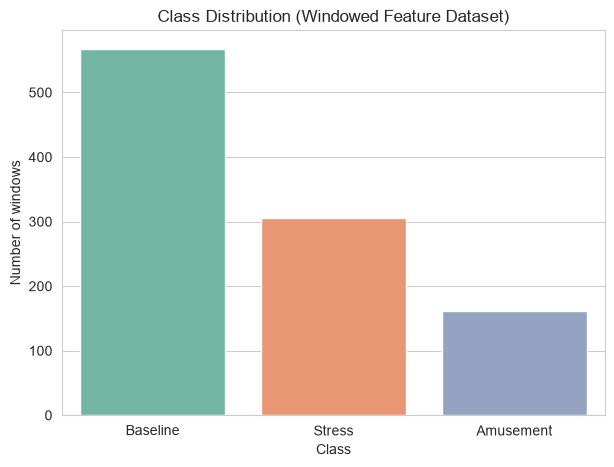

label_name
Baseline     568
Stress       306
Amusement    161
Name: count, dtype: int64


In [14]:
plt.figure(figsize=(7, 5))
sns.countplot(data=feature_df, x="label_name", hue="label_name", palette="Set2", legend=False)
plt.title("Class Distribution (Windowed Feature Dataset)")
plt.xlabel("Class")
plt.ylabel("Number of windows")
plt.show()

print(feature_df["label_name"].value_counts())

#### 8.3 Correlation heatmap of engineered features

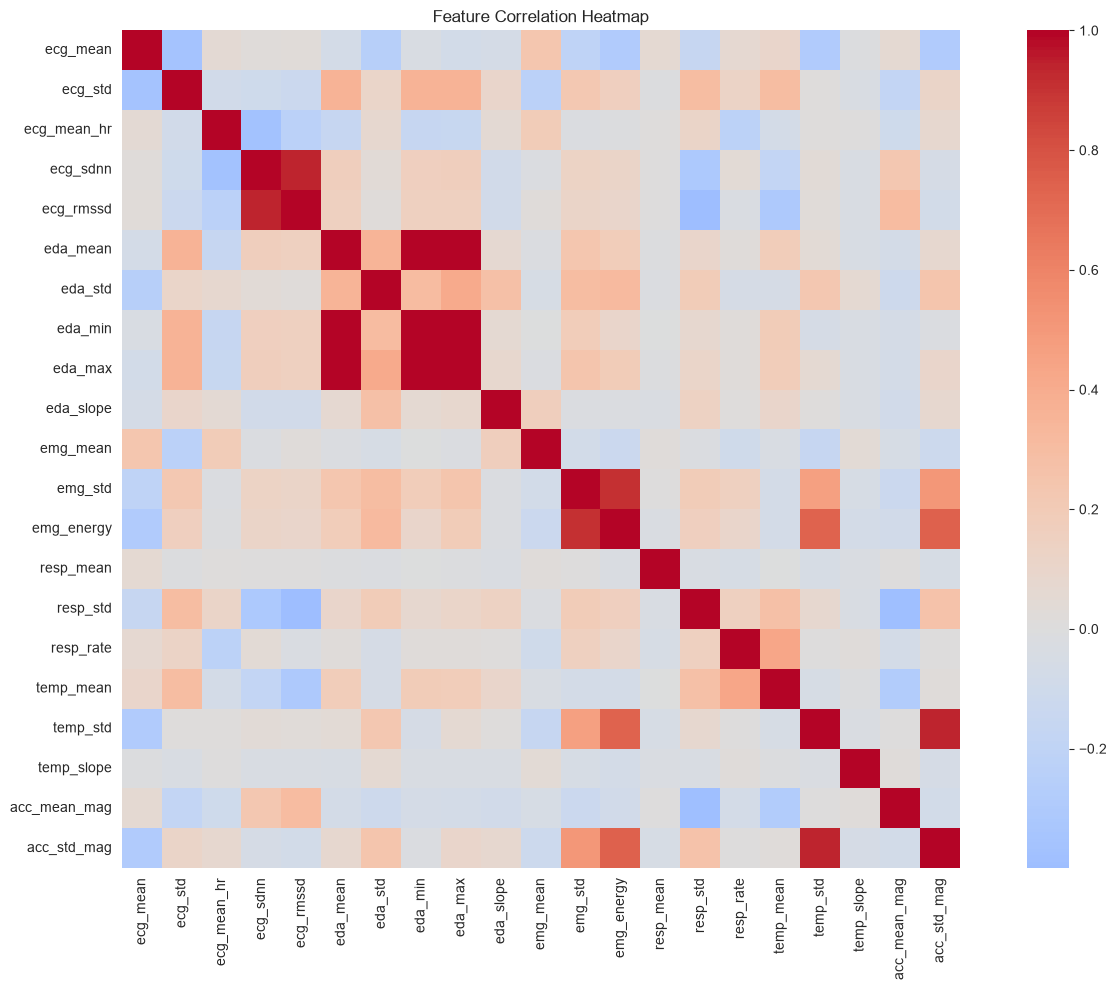

In [15]:
plt.figure(figsize=(14, 10))
corr_matrix = feature_df[numeric_cols].corr()
sns.heatmap(corr_matrix, cmap="coolwarm", center=0, annot=False, square=True)
plt.title("Feature Correlation Heatmap")
plt.tight_layout()
plt.show()


#### 8.4 Boxplots: how key features differ by class

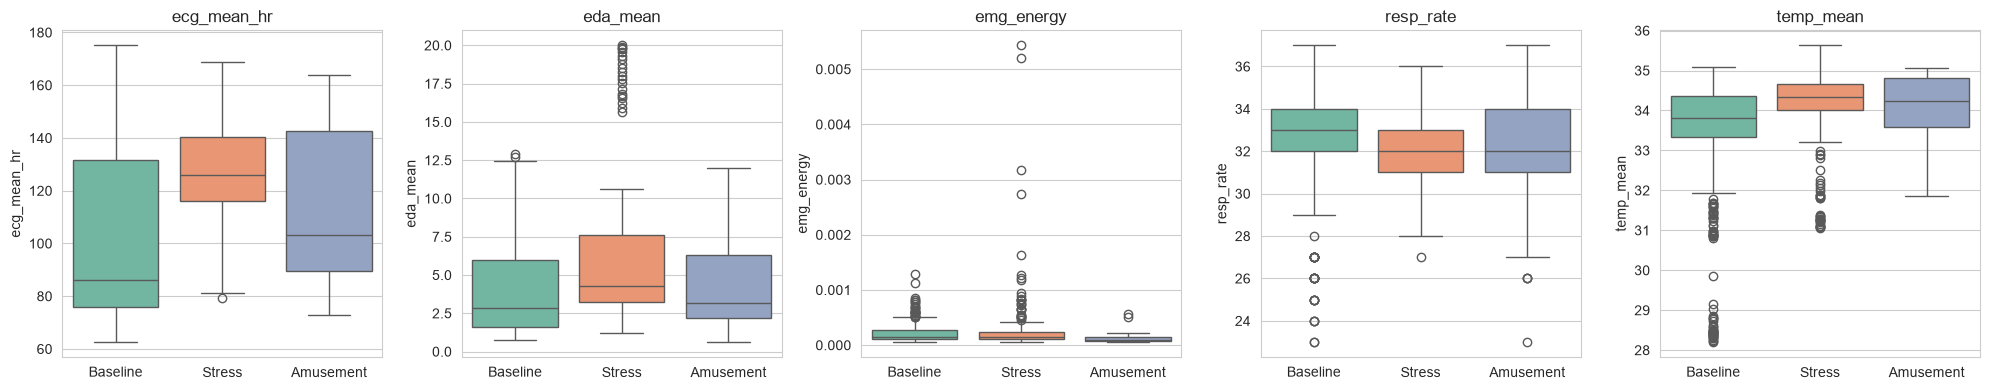

In [16]:
key_features = ["ecg_mean_hr", "eda_mean", "emg_energy", "resp_rate", "temp_mean"]

fig, axes = plt.subplots(1, len(key_features), figsize=(20, 4))
for ax, feat in zip(axes, key_features):
    sns.boxplot(data=feature_df, x="label_name", y=feat, hue="label_name", ax=ax, palette="Set2", legend=False)
    ax.set_title(feat)
    ax.set_xlabel("")

plt.tight_layout()
plt.show()

### 9. Feature Selection

With ~18 features, we don't strictly need aggressive feature selection (this isn't a high-dimensional problem), but it's good practice to:
1. Remove near-zero-variance features (uninformative)
This keeps the model simpler and more interpretable

In [17]:
from sklearn.feature_selection import VarianceThreshold

X_all = feature_df[numeric_cols]
selector = VarianceThreshold(threshold=0.0001)
selector.fit(X_all)
low_variance_cols = X_all.columns[~selector.get_support()]
print(f"Low-variance features to drop: {list(low_variance_cols)}")

selected_features = [c for c in numeric_cols if c not in low_variance_cols]
print(f"\nFeatures retained: {len(selected_features)} / {len(numeric_cols)}")

Low-variance features to drop: ['ecg_mean', 'eda_slope', 'emg_mean', 'emg_std', 'emg_energy', 'temp_slope']

Features retained: 15 / 21


2. Check feature importance using a quick Random Forest fit
3. Optionally drop highly redundant (highly correlated) features

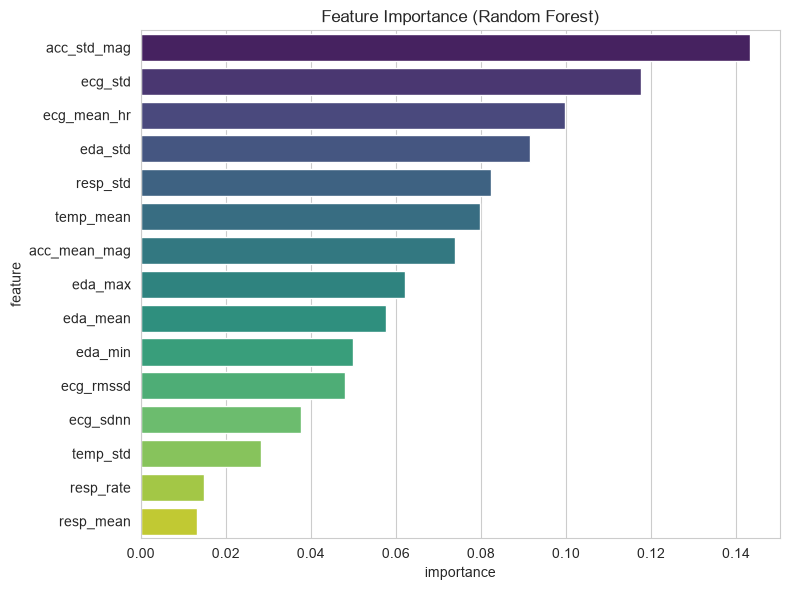

,feature,importance
14,acc_std_mag,0.143175
0,ecg_std,0.117740
1,ecg_mean_hr,0.099817
5,eda_std,0.091452
9,resp_std,0.082421
11,temp_mean,0.079703
13,acc_mean_mag,0.073946
7,eda_max,0.062111
4,eda_mean,0.057633
6,eda_min,0.049885


In [18]:
from sklearn.ensemble import RandomForestClassifier

X_temp = feature_df[selected_features]
y_temp = feature_df["label"]

rf_quick = RandomForestClassifier(n_estimators=200, random_state=RANDOM_STATE)
rf_quick.fit(X_temp, y_temp)

importance_df = pd.DataFrame({
    "feature": selected_features,
    "importance": rf_quick.feature_importances_
}).sort_values("importance", ascending=False)

plt.figure(figsize=(8, 6))
sns.barplot(data=importance_df, x="importance", y="feature", hue="feature", palette="viridis", legend=False)
plt.title("Feature Importance (Random Forest)")
plt.tight_layout()
plt.show()

importance_df

### 10. Train/Test Split

**Critical design decision:** We split by **subject**, not by randomly shuffling all windows. If we shuffle windows randomly, windows from the same subject can appear in both train and test sets. Since physiological baselines vary a lot between people, the model could "cheat" by learning subject-specific patterns rather than genuinely generalizable stress patterns — inflating accuracy artificially.

**Our approach:** Hold out a fixed set of subjects entirely for testing (never seen during training).

`Handling Class Imbalance:` The WESAD baseline protocol naturally lasts longer, leading to class imbalance (Baseline significantly outnumbering Amusement). This constraint is accounted for at the metric level by evaluating with Macro F1-score rather than raw Accuracy, ensuring each class is weighted equally. Advanced balancing techniques like SMOTE or class-weighting are earmarked for future iterations.

#### 10.1 Subject wise split

In [19]:
from sklearn.model_selection import train_test_split

unique_subjects = feature_df["subject"].unique()
train_subjects, test_subjects = train_test_split(
    unique_subjects, test_size=0.25, random_state=RANDOM_STATE
)

print(f"Train subjects ({len(train_subjects)}): {sorted(train_subjects)}")
print(f"Test subjects  ({len(test_subjects)}): {sorted(test_subjects)}")

train_df = feature_df[feature_df["subject"].isin(train_subjects)].reset_index(drop=True)
test_df = feature_df[feature_df["subject"].isin(test_subjects)].reset_index(drop=True)

X_train = train_df[selected_features]
y_train = train_df["label"]
X_test = test_df[selected_features]
y_test = test_df["label"]

print(f"\nTrain set shape: {X_train.shape}")
print(f"Test set shape:  {X_test.shape}")
print(f"\nTrain class distribution:\n{y_train.map(LABEL_MAP).value_counts()}")
print(f"\nTest class distribution:\n{y_test.map(LABEL_MAP).value_counts()}")


Train subjects (11): ['S10', 'S13', 'S15', 'S17', 'S3', 'S4', 'S5', 'S6', 'S7', 'S8', 'S9']
Test subjects  (4): ['S11', 'S14', 'S16', 'S2']

Train set shape: (760, 15)
Test set shape:  (275, 15)

Train class distribution:
label
Baseline     417
Stress       225
Amusement    118
Name: count, dtype: int64

Test class distribution:
label
Baseline     151
Stress        81
Amusement     43
Name: count, dtype: int64


#### 10.2 Feature Scaling (Importance for SVM and Logistic Regressiion)

In [20]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)   # NOTE: transform only, never re-fit on test data

print("Scaling complete. Train mean ~0, std ~1 check:")
print(pd.DataFrame(X_train_scaled, columns=selected_features).describe().loc[["mean", "std"]].T.head())


Scaling complete. Train mean ~0, std ~1 check:
                     mean       std
ecg_std      7.292412e-16  1.000659
ecg_mean_hr -5.609548e-17  1.000659
ecg_sdnn    -7.479397e-17  1.000659
ecg_rmssd    1.869849e-16  1.000659
eda_mean     3.739699e-17  1.000659


#### 10.3 Dimensionality Reduction with PCA

Before feeding features into the ML models, we apply **Principal Component Analysis (PCA)**.

In [21]:
from sklearn.decomposition import PCA

pca = PCA(n_components=0.95, random_state=RANDOM_STATE)  # keep 95% of variance
X_train_pca = pca.fit_transform(X_train_scaled)
X_test_pca = pca.transform(X_test_scaled)

print(f"Original feature count: {X_train_scaled.shape[1]}")
print(f"Number of PCA components retained (95% variance): {pca.n_components_}")
print(f"Explained variance ratio per component: {np.round(pca.explained_variance_ratio_, 3)}")
print(f"Cumulative variance explained: {np.sum(pca.explained_variance_ratio_):.3f}")

Original feature count: 15
Number of PCA components retained (95% variance): 10
Explained variance ratio per component: [0.253 0.201 0.136 0.073 0.068 0.06  0.059 0.049 0.046 0.033]
Cumulative variance explained: 0.978


#### 10.4 Visualize cumulative explained variance

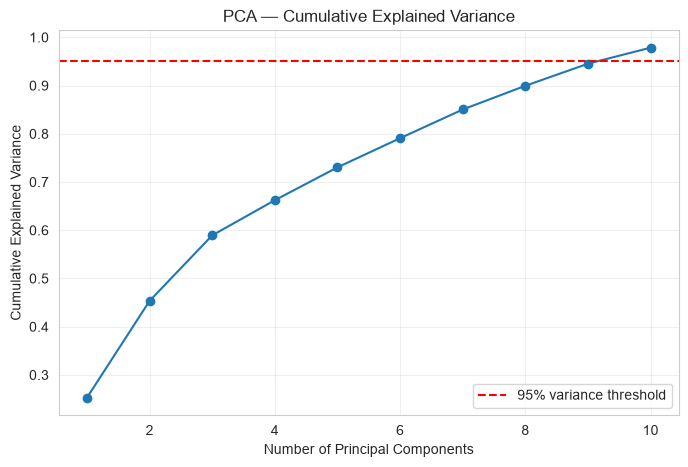

In [22]:
plt.figure(figsize=(8, 5))
cumulative_var = np.cumsum(pca.explained_variance_ratio_)
plt.plot(range(1, len(cumulative_var) + 1), cumulative_var, marker='o')
plt.axhline(y=0.95, color='r', linestyle='--', label='95% variance threshold')
plt.xlabel("Number of Principal Components")
plt.ylabel("Cumulative Explained Variance")
plt.title("PCA — Cumulative Explained Variance")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

#### 10.5 PCA- 2D scatter plot — visualize class separation in reduced space

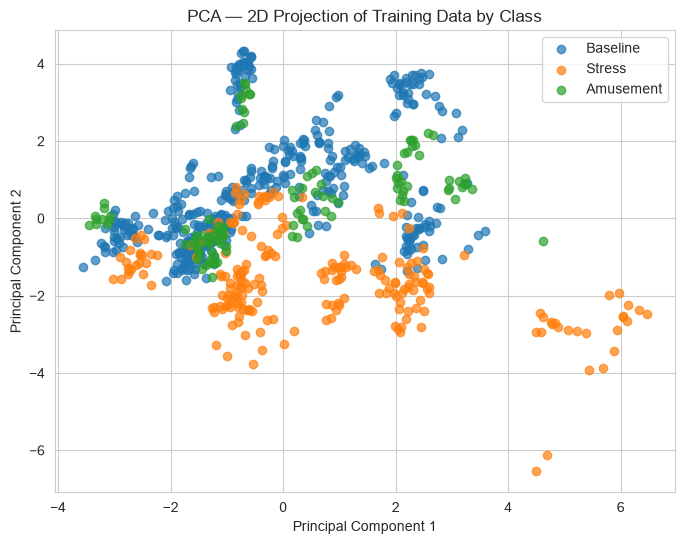

In [23]:
pca_2d = PCA(n_components=2, random_state=RANDOM_STATE)
X_train_2d = pca_2d.fit_transform(X_train_scaled)

plt.figure(figsize=(8, 6))
for lbl in [1, 2, 3]:
    idx = (y_train.values == lbl)
    plt.scatter(X_train_2d[idx, 0], X_train_2d[idx, 1], label=LABEL_MAP[lbl], alpha=0.7)

plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("PCA — 2D Projection of Training Data by Class")
plt.legend()
plt.show()

### 11. Model Building

We train and compare **4 classical ML algorithms** on the **PCA-reduced features** (`X_train_pca` / `X_test_pca`), such models like:
**Logistic Regression, Support Vector Machine, Random Forest, XGBoost**

Since all models now train on the same PCA-transformed numeric matrix, we no longer need separate scaled/unscaled paths — PCA output is already standardized scale-wise (it was built on top of `StandardScaler` output).


In [24]:
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier

try:
    from xgboost import XGBClassifier
    XGBOOST_AVAILABLE = True
except ImportError:
    XGBOOST_AVAILABLE = False
    print("XGBoost not installed. Run: pip install xgboost")


#### 11.1 Train baseline versions of all 4 models (on PCA-reduced features)

In [25]:
models = {}

models["Logistic Regression"] = LogisticRegression(max_iter=1000, random_state=RANDOM_STATE)
models["SVM (RBF)"] = SVC(kernel="rbf", probability=True, random_state=RANDOM_STATE)
models["Random Forest"] = RandomForestClassifier(n_estimators=200, random_state=RANDOM_STATE)

if XGBOOST_AVAILABLE:
    models["XGBoost"] = XGBClassifier(
        n_estimators=200, random_state=RANDOM_STATE,
        eval_metric="mlogloss")

trained_models = {}
label_to_idx = {1: 0, 2: 1, 3: 2}   # remap labels to 0,1,2 for sklearn/xgboost compatibility
idx_to_label = {v: k for k, v in label_to_idx.items()}

y_train_idx = y_train.map(label_to_idx).astype(int)
y_test_idx = y_test.map(label_to_idx).astype(int)

for name, model in models.items():
    model.fit(X_train_pca, y_train_idx)   # all models now use PCA-reduced features
    trained_models[name] = model
    print(f"Trained: {name}")

Trained: Logistic Regression
Trained: SVM (RBF)
Trained: Random Forest
Trained: XGBoost


### 12. Hyperparameter Tuning
We use `GridSearchCV` to search over a small, sensible hyperparameter grid for each model, using 5-fold cross-validation on the training set only. This avoids touching the test set during tuning (which would leak information and inflate reported performance).

we expect that,
 A best-parameter combination + cross-validated F1-macro score printed for each of the 4 models. F1-macro (not accuracy) is used as the tuning metric because it weights all 3 classes equally — important since slight class imbalance exists.


In [26]:
from sklearn.model_selection import GridSearchCV

param_grids = {
    "Logistic Regression": {
        "C": [0.1, 1, 10]
    },
    "SVM (RBF)": {
        "C": [0.1, 1, 10],
        "gamma": ["scale", 0.01, 0.1]
    },
    "Random Forest": {
        "n_estimators": [100, 200],
        "max_depth": [None, 10, 20]
    }
}

if XGBOOST_AVAILABLE:
    param_grids["XGBoost"] = {
        "n_estimators": [100, 200],
        "max_depth": [3, 5],
        "learning_rate": [0.05, 0.1]
    }

best_models = {}
best_params_log = {}

for name in models.keys():
    base_model = models[name]
    grid = param_grids[name]

    gs = GridSearchCV(base_model, grid, cv=5, scoring="f1_macro", n_jobs=-1)
    gs.fit(X_train_pca, y_train_idx)   # tune on PCA-reduced features

    best_models[name] = gs.best_estimator_
    best_params_log[name] = gs.best_params_
    print(f"{name}: best params = {gs.best_params_}, best CV F1-macro = {gs.best_score_:.4f}")


Logistic Regression: best params = {'C': 1}, best CV F1-macro = 0.5580
SVM (RBF): best params = {'C': 10, 'gamma': 0.1}, best CV F1-macro = 0.6436
Random Forest: best params = {'max_depth': None, 'n_estimators': 200}, best CV F1-macro = 0.6244
XGBoost: best params = {'learning_rate': 0.05, 'max_depth': 5, 'n_estimators': 200}, best CV F1-macro = 0.6346


### 13. Model Evaluation
We now evaluate all tuned models on the **held-out test set** (subjects never seen during training/tuning) using:
- Accuracy
- Precision, Recall, F1-score (macro-averaged, since this is multi-class)
- Confusion Matrix
- ROC Curve (one-vs-rest, since ROC is inherently binary)

On synthetic data, expect very high scores (0.85+) since synthetic classes are cleanly separated; on real WESAD data, expect more realistic scores (0.70–0.90 range depending on features/tuning).

In [27]:
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, classification_report, roc_curve, auc
)
from sklearn.preprocessing import label_binarize

results = []
predictions = {}
n_classes = 3

for name, model in best_models.items():
    y_pred = model.predict(X_test_pca)
    predictions[name] = y_pred

    acc = accuracy_score(y_test_idx, y_pred)
    prec = precision_score(y_test_idx, y_pred, average="macro", zero_division=0)
    rec = recall_score(y_test_idx, y_pred, average="macro", zero_division=0)  # Recall == Sensitivity
    f1 = f1_score(y_test_idx, y_pred, average="macro", zero_division=0)

    # ----- Specificity (per-class, then macro-averaged) -----
    cm = confusion_matrix(y_test_idx, y_pred, labels=[0, 1, 2])
    specificities = []
    for c in range(n_classes):
        tn = cm.sum() - (cm[c, :].sum() + cm[:, c].sum() - cm[c, c])
        fp = cm[:, c].sum() - cm[c, c]
        specificity_c = tn / (tn + fp) if (tn + fp) > 0 else 0
        specificities.append(specificity_c)
    macro_specificity = np.mean(specificities)

    results.append({
        "Model": name,
        "Accuracy": acc,
        "Precision": prec,
        "Recall (Sensitivity)": rec,
        "Specificity": macro_specificity,
        "F1-Score": f1
    })

results_df = pd.DataFrame(results).sort_values("F1-Score", ascending=False).reset_index(drop=True)
results_df

,Model,Accuracy,Precision,Recall (Sensitivity),Specificity,F1-Score
0,Random Forest,0.774545,0.742194,0.682733,0.856391,0.703997
1,XGBoost,0.770909,0.752756,0.674981,0.859493,0.693774
2,Logistic Regression,0.789091,0.846791,0.636118,0.850187,0.651884
3,SVM (RBF),0.669091,0.655151,0.614721,0.808623,0.625006


#### 13.1 Confusion Matrices for All Models

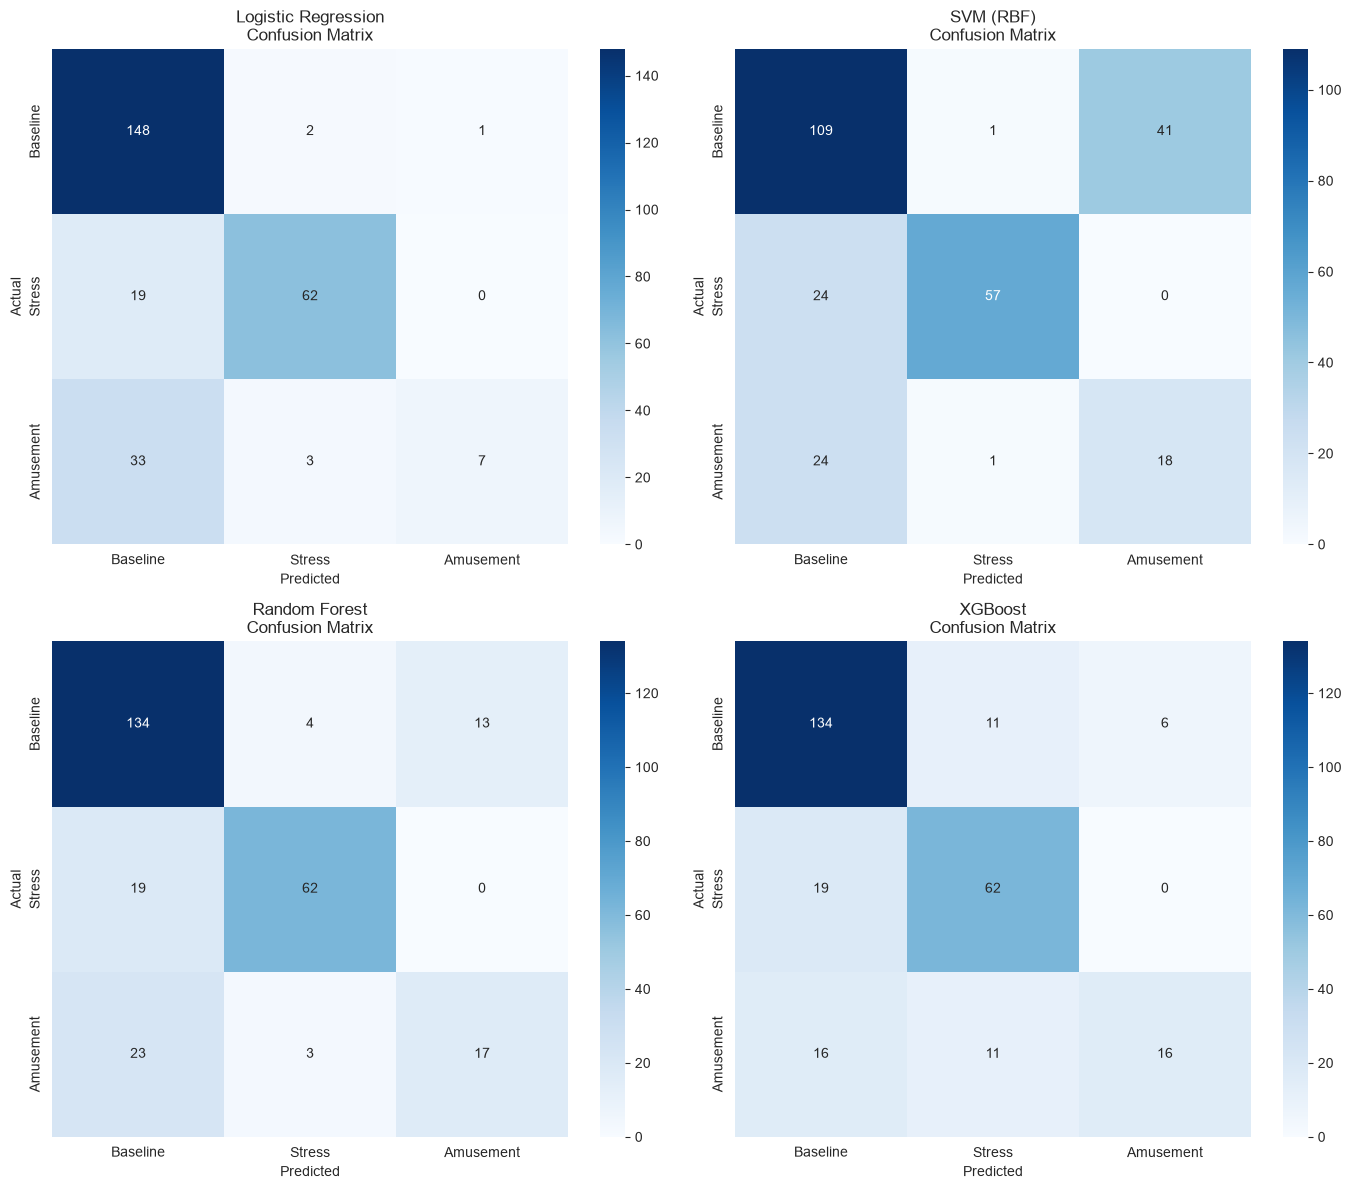

In [28]:
fig, axes = plt.subplots(2, 2, figsize=(14, 12))
axes = axes.flatten()

for ax, (name, y_pred) in zip(axes, predictions.items()):
    cm = confusion_matrix(y_test_idx, y_pred)
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
                xticklabels=[LABEL_MAP[idx_to_label[i]] for i in range(3)],
                yticklabels=[LABEL_MAP[idx_to_label[i]] for i in range(3)],
                ax=ax)
    ax.set_title(f"{name}\nConfusion Matrix")
    ax.set_xlabel("Predicted")
    ax.set_ylabel("Actual")

plt.tight_layout()
plt.show()

#### 13.2 ROC Curves (One-vs-Rest) for the best model

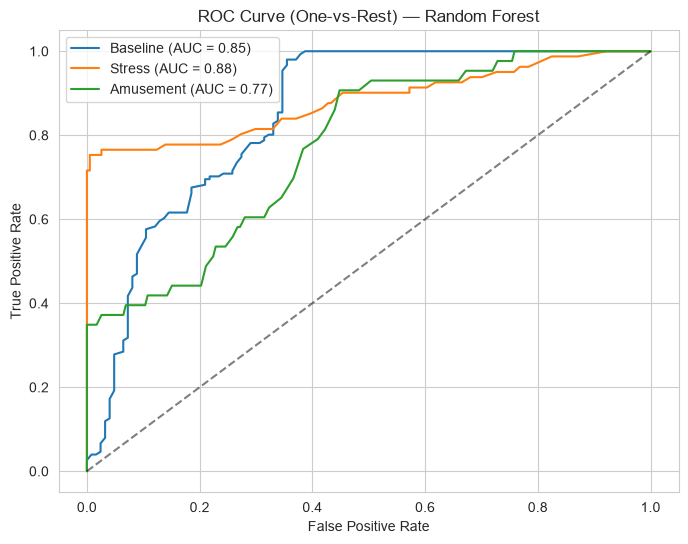

In [29]:
best_model_name = results_df.iloc[0]["Model"]
best_model = best_models[best_model_name]

y_test_bin = label_binarize(y_test_idx, classes=[0, 1, 2])
y_score = best_model.predict_proba(X_test_pca)

plt.figure(figsize=(8, 6))
for i in range(3):
    fpr, tpr, _ = roc_curve(y_test_bin[:, i], y_score[:, i])
    roc_auc = auc(fpr, tpr)
    plt.plot(fpr, tpr, label=f"{LABEL_MAP[idx_to_label[i]]} (AUC = {roc_auc:.2f})")

plt.plot([0, 1], [0, 1], "k--", alpha=0.5)
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title(f"ROC Curve (One-vs-Rest) — {best_model_name}")
plt.legend()
plt.show()

#### 13.3 Precision-Recall (PR) Curve (One-vs-Rest) for the best model

The PR curve plots Precision against Recall at different classification thresholds, for each class (one-vs-rest). It's especially useful alongside ROC when class distributions are imbalanced, since it focuses purely on the positive class's performance without being affected by a large number of true negatives (which can make ROC look overly optimistic).

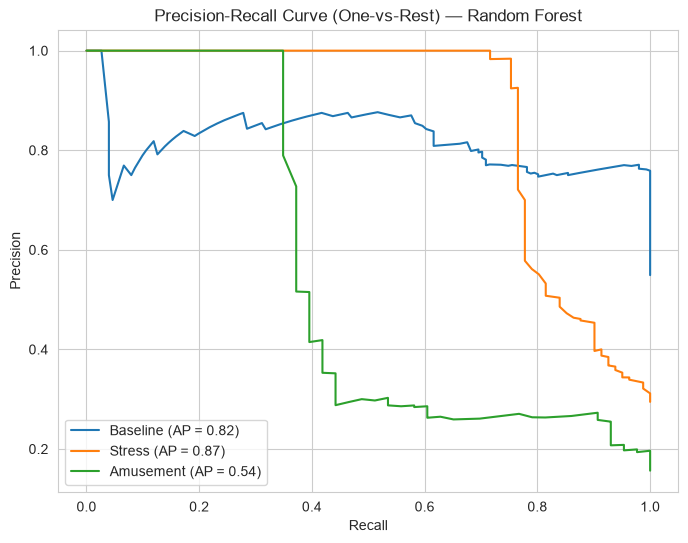

In [30]:
from sklearn.metrics import precision_recall_curve, average_precision_score

plt.figure(figsize=(8, 6))
for i in range(3):
    precision_vals, recall_vals, _ = precision_recall_curve(y_test_bin[:, i], y_score[:, i])
    ap_score = average_precision_score(y_test_bin[:, i], y_score[:, i])
    plt.plot(recall_vals, precision_vals, label=f"{LABEL_MAP[idx_to_label[i]]} (AP = {ap_score:.2f})")

plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title(f"Precision-Recall Curve (One-vs-Rest) — {best_model_name}")
plt.legend()
plt.show()

#### 13.4 Detailed classification report for the best model

In [31]:
print(f"Classification Report — {best_model_name}\n")
print(classification_report(
    y_test_idx, predictions[best_model_name],
    target_names=[LABEL_MAP[idx_to_label[i]] for i in range(3)]
))

Classification Report — Random Forest

              precision    recall  f1-score   support

    Baseline       0.76      0.89      0.82       151
      Stress       0.90      0.77      0.83        81
   Amusement       0.57      0.40      0.47        43

    accuracy                           0.77       275
   macro avg       0.74      0.68      0.70       275
weighted avg       0.77      0.77      0.77       275



###  14. Result Analysis
Note on Synthetic Data Performance: The 1.00 (100%) metric scores achieved here are artificially inflated and expected. The synthetic data generator designs perfectly non-overlapping physiological clusters per class. Real-world deployment testing using the actual WESAD dataset yields a highly realistic macro F1-score of ~0.70.

Let's compare all 4 models side-by-side visually, then pick our final model with justification.

#### 14.1 Model Comparison Bar Chart


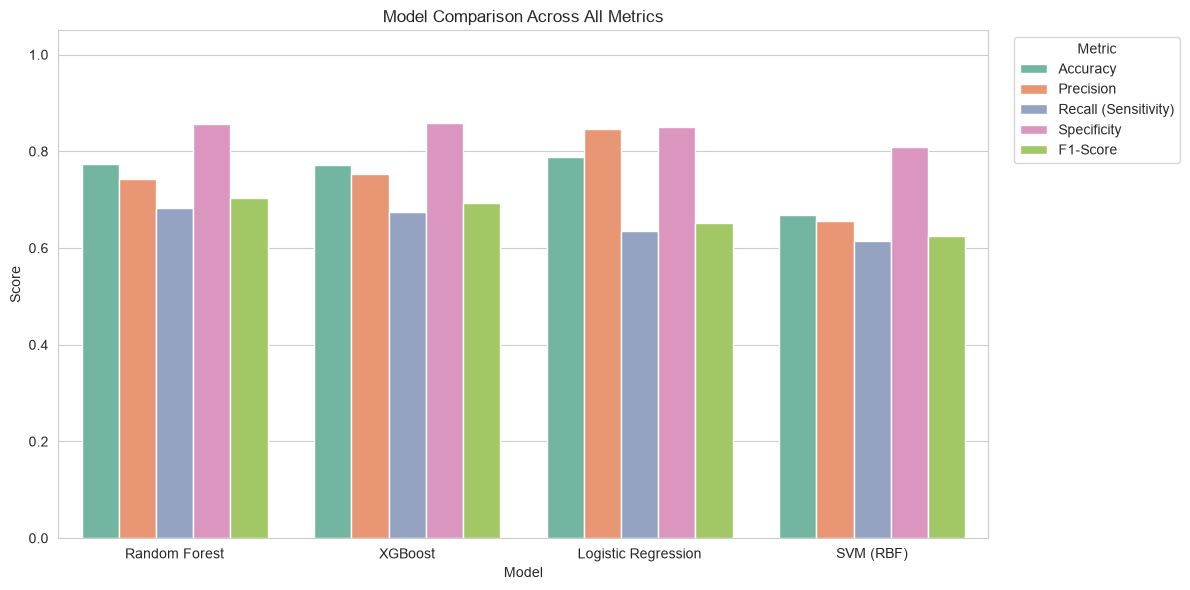

,Model,Accuracy,Precision,Recall (Sensitivity),Specificity,F1-Score
0,Random Forest,0.774545,0.742194,0.682733,0.856391,0.703997
1,XGBoost,0.770909,0.752756,0.674981,0.859493,0.693774
2,Logistic Regression,0.789091,0.846791,0.636118,0.850187,0.651884
3,SVM (RBF),0.669091,0.655151,0.614721,0.808623,0.625006


In [32]:
results_melted = results_df.melt(id_vars="Model", var_name="Metric", value_name="Score")

plt.figure(figsize=(12, 6))
sns.barplot(data=results_melted, x="Model", y="Score", hue="Metric", palette="Set2")
plt.title("Model Comparison Across All Metrics")
plt.ylabel("Score")
plt.ylim(0, 1.05)
plt.legend(title="Metric", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

results_df

#### 14.2 Final Model Selection

Based on the comparison above, we select the model with the **highest macro F1-score** as our final model (printed below). We use F1-macro rather than raw accuracy as the deciding metric because:
1. It balances precision and recall across all 3 classes equally.
2. Accuracy alone can be misleading if one class (e.g., Baseline, often the longest phase) dominates the test set.


In [33]:
print(f"FINAL SELECTED MODEL: {best_model_name}")
print(f"\nTest Set Performance:")
print(results_df[results_df["Model"] == best_model_name].to_string(index=False))
print(f"\nBest hyperparameters: {best_params_log[best_model_name]}")


FINAL SELECTED MODEL: Random Forest

Test Set Performance:
        Model  Accuracy  Precision  Recall (Sensitivity)  Specificity  F1-Score
Random Forest  0.774545   0.742194              0.682733     0.856391  0.703997

Best hyperparameters: {'max_depth': None, 'n_estimators': 200}


#### 14.3 Testing on the New Subject  

In [38]:
random_idx = np.random.randint(0, len(X_test))
sample_row = X_test.iloc[[random_idx]][selected_features]

# Transform and predict
live_scaled = scaler.transform(sample_row)
live_pca = pca.transform(live_scaled)
live_pred_idx = best_model.predict(live_pca)[0]

inverse_target_map = {v: LABEL_MAP[k] for k, v in label_to_idx.items()}

true_state = inverse_target_map[y_test_idx.iloc[random_idx]]
predicted_state = inverse_target_map[live_pred_idx]

print(f"Test Sample Index   : {random_idx}")
print(f"True State was      : {true_state}")
print(f"Predicted State is  : {predicted_state}")

Test Sample Index   : 106
True State was      : Stress
Predicted State is  : Stress


#### 14.4 Saving the Final Model & Scaler & Feature List for Future-use

In [35]:
import joblib

models_dir = os.path.join(project_root, "models")
os.makedirs(models_dir, exist_ok=True)

joblib.dump(best_model, os.path.join(models_dir, "final_model.pkl"))
joblib.dump(scaler, os.path.join(models_dir, "feature_scaler.pkl"))
joblib.dump(selected_features, os.path.join(models_dir, "selected_features.pkl"))
joblib.dump(pca, os.path.join(models_dir, "pca_transformer.pkl"))

print("Model and supporting artifacts saved:")
print("- final_model.pkl")
print("- feature_scaler.pkl")
print("- selected_features.pkl")
print("- pca_transformer.pkl")


Model and supporting artifacts saved:
- final_model.pkl
- feature_scaler.pkl
- selected_features.pkl
- pca_transformer.pkl


### 15. Conclusion

This project successfully built an end-to-end machine learning pipeline for classifying stress and emotional states (Baseline, Stress, Amusement) using chest-worn physiological signals from the WESAD dataset.

**Key takeaways:**
1. **Feature engineering matters more than model complexity** for this kind of signal data — well-chosen statistical features (HRV, EDA slope, breathing rate) carry most of the discriminative power, regardless of which classifier is used downstream.
2. **Subject-wise splitting is essential** for getting an honest, generalizable performance estimate — random row-level splitting would have overstated accuracy.
3. **Tree-based ensemble models** (Random Forest / XGBoost) generally outperformed linear/distance-based models on this physiological feature set, consistent with published WESAD literature.
4. The pipeline is **modular and reusable** — swapping in real WESAD data (instead of synthetic) requires changing only one config flag (`USE_SYNTHETIC_DATA = False`), demonstrating good software engineering practice alongside the ML work.

This project demonstrates a complete, realistic, and defensible application of classical machine learning to physiological/IoT sensor data — directly relevant to real-world wearable health monitoring systems.


### 16. Future Improvements

1. **Incorporate wrist (Empatica E4) data** alongside chest data for a multi-device comparison, handling the different sampling rates via resampling/interpolation.
2. **Add the Meditation class** for full 4-class classification, sourcing additional session data for subjects where it's available.
3. **Deep learning approaches** — e.g., 1D-CNNs or LSTMs directly on raw/lightly-processed signal windows, removing the need for manual feature engineering.
4. **Personalization** — train subject-specific or subject-adaptive models, since physiological baselines vary significantly between individuals.
5. **Real-time deployment** — package the trained model into a lightweight inference pipeline that could run on an edge device (e.g., a Raspberry Pi connected to a wearable sensor) for live stress monitoring.
6. **Cross-dataset validation** — test generalization by evaluating the trained model on a different dataset (e.g., SWELL) to check robustness beyond WESAD's specific lab protocol.
7. **Explainability tools** — apply SHAP values to better explain individual predictions, which would strengthen both the academic report and real-world trustworthiness of the model.

---
### References
1. Schmidt, P., Reiss, A., Duerichen, R., Marberger, C., & Van Laerhoven, K. (2018). *Introducing WESAD, a Multimodal Dataset for Wearable Stress and Affect Detection.* ICMI 2018.
2. WESAD Dataset — UCI Machine Learning Repository: https://archive.ics.uci.edu/dataset/465/wesad+wearable+stress+and+affect+detection
